In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ml_library.preprocessing.empty_values_remove import empty_values_remove

# **Projeto Final — Aprendizado de Máquina I (2026.2) · Parte II: aplicação**
### Grupo: *Machine Learning Name in progress*

- Tipo de problema: **Regressão**
- Conjunto de dados: [**SRAG — Sivep-Gripe**](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026)
- Objetivo principal: **estimar as notificações semanais de Síndrome Respiratória Aguda Grave (SRAG) com Vírus Sincicial Respiratório (VSR) em bebês menores de 6 meses em um cenário de referência sem a campanha de vacinação materna**


- **Equipe responsável**
    - Ryan Kevin
    - Gabriel Falcão
    - Lucas Silva
- **Revisão** 
    - Lucas Vieira
    - Mateus Almeida

## 0. Configuração e reprodutibilidade

- A base está em `data/vsr.csv` e contém cinco colunas.
- Usamos a biblioteca do grupo no commit `9d1cf513dbfba9341eda56f0e3b93e59d8ebfad6`, fixado em `pyproject.toml` e `uv.lock`.
- Execute as células em ordem, usando o ambiente `.venv` do projeto. A semente principal é 67.
- As tabelas e os gráficos são exibidos no notebook; não são exportados arquivos de resultados.

## 1. Problema e dados

**Pergunta de regressão:** se a relação observada antes da campanha de vacinação materna contra o VSR se mantivesse, quantas notificações semanais de SRAG com VSR esperaríamos em bebês de **0 a menos de 6 meses** em 2026?

- **Alvo:** contagem de notificações de SRAG com VSR no grupo de [0, 6) meses.
- **Entradas:** contagens de SRAG com VSR na mesma semana em [6, 12), [12, 24) e [24, 48) meses. Na modelagem, comparamos também a inclusão das contagens dessas faixas uma e duas semanas antes; não usamos defasagens do alvo.
- **Unidade de análise:** uma semana nacional, agrupada pela data dos primeiros sintomas.
- **Referência histórica:** usar dados anteriores à campanha do SUS, iniciada em 04/12/2025. Reservar um período anterior à campanha para o teste. O arquivo reúne os extratos de 2023 a 2026. Usar a data dos primeiros sintomas para separar o histórico anterior à campanha das semanas do cenário em 2026.

O cenário supõe que a relação histórica entre as faixas etárias se manteria. As faixas mais velhas servem como referência para a circulação do vírus. Como algumas crianças menores de 24 meses são elegíveis ao nirsevimabe (anticorpo para prevenir infecções graves de vsr), fazemos uma análise de sensibilidade: repetimos a análise usando apenas a faixa [24, 48) meses como referência e comparamos os resultados. A diferença entre o observado e o estimado depende dessa hipótese e pode refletir outras mudanças, como testagem e notificação. 
[Início da campanha](https://www.gov.br/saude/pt-br/assuntos/noticias/2025/dezembro/gestantes-ja-podem-se-vacinar-contra-a-bronquiolite)
[Nota técnica sobre nirsevimabe](https://www.gov.br/saude/pt-br/centrais-de-conteudo/publicacoes/notas-tecnicas/2026/nota-tecnica-conjunta-no-87-2026-svsa-saps-saes-sesai-ms.pdf/%40%40download/file)

### 1.1 Carregamento dos dados

O arquivo contém as notificações dos extratos de 2023 a 2026 para crianças de **até 4 anos completos**, ou seja, desde o nascimento até antes do quinto aniversário. O filtro de idade foi aplicado aos extratos originais. Nesta versão, foram mantidas as cinco colunas necessárias ao pipeline, preservando os valores das linhas selecionadas.

Como a idade é registrada: `NU_IDADE_N` é um número e `TP_IDADE` indica a unidade. Por exemplo, idade 4 com unidade 2 significa **4 meses**, enquanto idade 4 com unidade 3 significa **4 anos completos**. A idade é registrada na data dos primeiros sintomas.

| `TP_IDADE` | Unidade | Valores de `NU_IDADE_N` incluídos |
|---|---|---|
| 1 | Dias | 0 a 31 |
| 2 | Meses | 0 a 59 |
| 3 | Anos completos | 0 a 4 |

Registros com idade ausente ou unidade inválida ficam fora do recorte. Uma criança registrada com 4 anos entra na base, mas fica fora da faixa explicativa de **24 a menos de 48 meses**. A equipe usará as faixas de [0, 6), [6, 12), [12, 24) e [24, 48) meses ao construir o painel.


In [2]:
DATA_PATH = "data/vsr.csv"
df = pd.read_csv(DATA_PATH, sep=";", low_memory=False)
cobertura_datas = pd.to_datetime(df["DT_SIN_PRI"], format="mixed", utc=True).dt.tz_localize(None)
df.shape

(514225, 5)

### 1.2 Campos de referência e origem

| Coluna | Uso no pipeline |
|---|---|
| `DT_SIN_PRI` | Data dos primeiros sintomas. Usar para agrupar as notificações por semana. |
| `TP_IDADE`, `NU_IDADE_N` | Tipo e valor da idade. Usar em conjunto para construir as faixas etárias. |
| `PCR_VSR`, `AN_VSR` | Indicadores de detecção de VSR. Ao montar o alvo e as entradas, considerar positivo quando pelo menos um deles for 1 e contar a notificação uma vez. |

Extratos do Sivep-Gripe usados no CSV: [2023](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2023/INFLUD23-23-03-2026.parquet) e [2024](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2024/INFLUD24-23-03-2026.parquet), de 23/03/2026; [2025](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2025/INFLUD25-02-11-2026.parquet) e [2026](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026/resource/74091efc-3f75-42e8-a6fa-6b79a8d30582), de 02/11/2026. As 194 colunas dos extratos originais foram alinhadas pelo nome; o CSV distribuído contém apenas as cinco colunas descritas na tabela. Os extratos históricos em Parquet foram convertidos para CSV. [Dicionário de dados](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/dicionario-de-dados-2019-a-2025.pdf)

## 2. Análise exploratória (EDA)

### 2.1 Dimensões, tipos e primeiras linhas

Conferir datas, códigos de idade e valores dos indicadores de VSR.

In [3]:
# Primeiras linhas do dataset
print(f"Dataset com {df.shape[0]} linhas e {df.shape[1]} colunas:")
df.head()

Dataset com 514225 linhas e 5 colunas:


,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR
0,2023-01-16 00:00:00,7,2,1.0,NaN
1,2023-04-11 00:00:00,3,2,1.0,NaN
2,2023-08-07 00:00:00,3,3,NaN,NaN
3,2023-07-30 00:00:00,1,3,NaN,NaN
4,2023-08-24 00:00:00,19,1,1.0,NaN


Vamos padronizar o formato das datas

In [4]:
# Padronizando como AAAA-MM-DD
df['DT_SIN_PRI'] = pd.to_datetime(df['DT_SIN_PRI'], format='mixed', utc=True)
df['DT_SIN_PRI'] = df['DT_SIN_PRI'].dt.date
df['DT_SIN_PRI'] = pd.to_datetime(df['DT_SIN_PRI'])

In [5]:
# Informações básicas
print("Informações básicas do dataset:")
df.info()

Informações básicas do dataset:
<class 'pandas.DataFrame'>
RangeIndex: 514225 entries, 0 to 514224
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype        
---  ------      --------------   -----        
 0   DT_SIN_PRI  514225 non-null  datetime64[s]
 1   NU_IDADE_N  514225 non-null  int64        
 2   TP_IDADE    514225 non-null  int64        
 3   PCR_VSR     119047 non-null  float64      
 4   AN_VSR      33409 non-null   float64      
dtypes: datetime64[s](1), float64(2), int64(2)
memory usage: 19.6 MB


In [6]:
df.head()

,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR
0,2023-01-16,7,2,1.0,NaN
1,2023-04-11,3,2,1.0,NaN
2,2023-08-07,3,3,NaN,NaN
3,2023-07-30,1,3,NaN,NaN
4,2023-08-24,19,1,1.0,NaN


### 2.2 Valores ausentes

Verificar datas e indicadores ausentes. Campo de exame vazio não equivale a um teste negativo.

In [7]:
# Qtd. de valores ausentes
print("Quantidade de valores ausentes por coluna:")
print(df.isna().sum())

Quantidade de valores ausentes por coluna:
DT_SIN_PRI         0
NU_IDADE_N         0
TP_IDADE           0
PCR_VSR       395178
AN_VSR        480816
dtype: int64


Linhas com NaN em 'PCR_VSR' e 'AN_VSR' não permitem concluir se houve resultado positivo ou negativo.

Removemos as linhas com os dois campos ausentes e mantemos somente aquelas com pelo menos um resultado igual a 1. A mesma notificação é contada uma única vez.

In [8]:
# Remove linhas com duplo NaN em 'PCR_VSR' e 'AN_VSR'
df = empty_values_remove(df, ['PCR_VSR', 'AN_VSR'], any_missing=False)
# Mantém somente notificações positivas em pelo menos um exame.
df = df.loc[df['PCR_VSR'].eq(1) | df['AN_VSR'].eq(1)].copy()
print(f"Número de crianças com pelo menos um positivo: {df.shape[0]}")

Número de crianças com pelo menos um positivo: 143505


In [9]:
print("Quantidade de valores ausentes por coluna pós filtração:")
print(df.isna().sum())

Quantidade de valores ausentes por coluna pós filtração:
DT_SIN_PRI         0
NU_IDADE_N         0
TP_IDADE           0
PCR_VSR        24458
AN_VSR        110096
dtype: int64


### 2.3 Distribuição da variável-alvo

Explorar as contagens semanais de 0 a <6 meses no período de desenvolvimento.

In [10]:
# Calcular número de crianças com menos de seis meses.
df_6_meses = df[(df['TP_IDADE'] == 1) | ((df['TP_IDADE'] == 2) & (df['NU_IDADE_N'] < 6))]
print(f"Há {df_6_meses.shape[0]} crianças de 0 a menos de seis meses no banco de dados em um total de {df.shape[0]}.")

Há 70818 crianças de 0 a menos de seis meses no banco de dados em um total de 143505.


In [11]:
# Agrupando casos de vsr do grupo-alvo por semana, no desenvolvimento
contagem_semanal = df_6_meses.resample('W-SAT', on='DT_SIN_PRI').size()
contagem_semanal = contagem_semanal[contagem_semanal.index < pd.Timestamp('2025-01-04')]

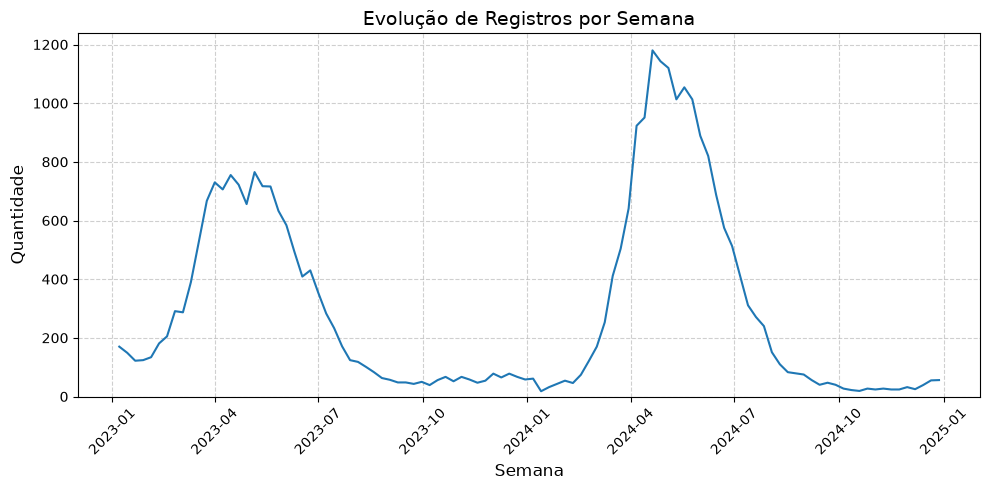

In [12]:
# Plotando gráfico de número de casos semanais do alvo no desenvolvimento
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(contagem_semanal.index, contagem_semanal.values)

ax.set_title('Evolução de Registros por Semana', fontsize=14)
ax.set_xlabel('Semana', fontsize=12)
ax.set_ylabel('Quantidade', fontsize=12)

plt.xticks(rotation=45)

ax.set_ylim(bottom=0)

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

A partir desse gráfico podemos observar o comportamento sazonal da doença no período de desenvolvimento.

### 2.4 Relação entre variáveis

Investigar correlação e colinearidade entre as contagens semanais.

In [13]:
# Pondo todas as idades em meses.
condicoes = [
    df['TP_IDADE'] == 1,  # Dias
    df['TP_IDADE'] == 2,  # Meses
    df['TP_IDADE'] == 3,  # Anos
]
escolhas = [df['NU_IDADE_N'] / 30.4375, df['NU_IDADE_N'], df['NU_IDADE_N'] * 12]
df['IDADE_MESES'] = np.select(condicoes, escolhas, default=np.nan)

In [14]:
df.head()

,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR,IDADE_MESES
0,2023-01-16,7,2,1.0,NaN,7.000000
1,2023-04-11,3,2,1.0,NaN,3.000000
2,2023-08-24,19,1,1.0,NaN,0.624230
3,2023-06-08,5,2,1.0,NaN,5.000000
4,2023-03-29,20,1,1.0,NaN,0.657084


In [15]:
# Criando classes de faixa etária no dataframe de 0 a 6, 6 a 12, 12 a 24 e 24 a 48 meses de idade.
limites = [0, 6, 12, 24, 48]
rotulos = ['0-6', '6-12', '12-24', '24-48']
df['FAIXA_ETARIA'] = pd.cut(
    df['IDADE_MESES'], bins=limites, labels=rotulos, right=False
)

In [16]:
# Calculando número de casos semanais para cada faixa etária
contagem_semanal = (
    df.groupby([pd.Grouper(key='DT_SIN_PRI', freq='W-SAT'), 'FAIXA_ETARIA'], observed=False)
    .size()
    .unstack(fill_value=0)
)

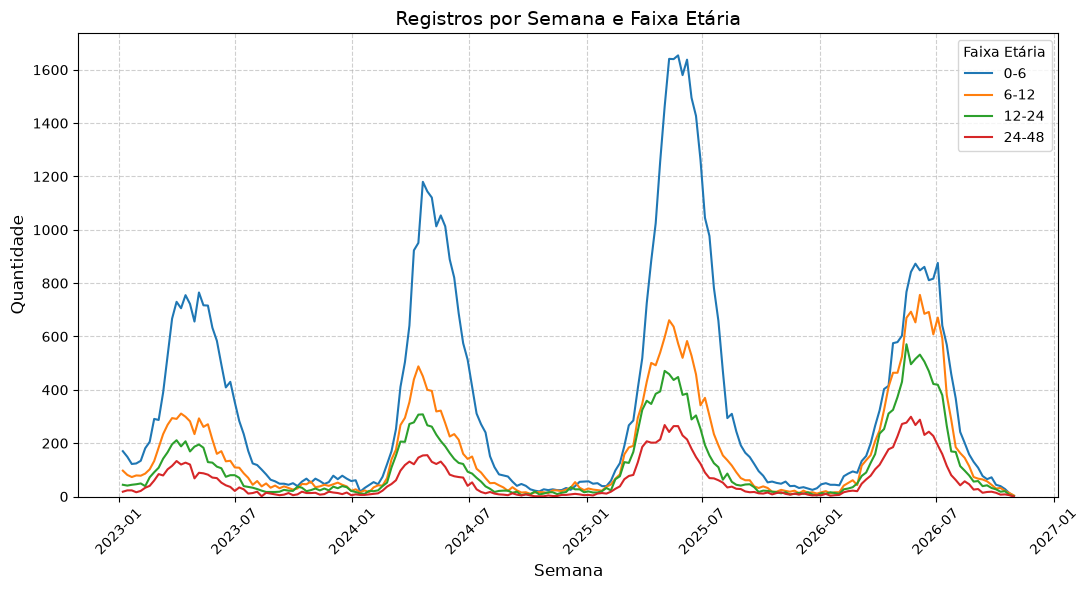

In [17]:
# Plotando número de casos semanais por faixa etária de 2023 a 2026.
fig, ax = plt.subplots(figsize=(11, 6))

for faixa in rotulos:
    ax.plot(
        contagem_semanal.index,
        contagem_semanal[faixa],
        label=faixa,
    )

# 6. Personalizar layout e eixos
ax.set_title('Registros por Semana e Faixa Etária', fontsize=14)
ax.set_xlabel('Semana', fontsize=12)
ax.set_ylabel('Quantidade', fontsize=12)
ax.legend(title='Faixa Etária')

plt.xticks(rotation=45)
ax.set_ylim(bottom=0)

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [18]:
# Calculando correlação entre faixas etárias
matriz_correlacao = contagem_semanal.corr(method='pearson')

print('Matriz de Correlação Semanal entre Faixas Etárias:')
print(matriz_correlacao.round(2))

Matriz de Correlação Semanal entre Faixas Etárias:
FAIXA_ETARIA   0-6  6-12  12-24  24-48
FAIXA_ETARIA                          
0-6           1.00  0.88   0.84   0.84
6-12          0.88  1.00   0.99   0.98
12-24         0.84  0.99   1.00   0.99
24-48         0.84  0.98   0.99   1.00


In [19]:
# Calculando matriz de correlação com corte antes da campanha
contagem_ate_2026 = contagem_semanal[contagem_semanal.index <= pd.Timestamp('2025-11-29')] # Casos por semana até 29/11/2025.

matriz_correlacao = contagem_ate_2026.corr(method='pearson')

print('Matriz de correlação semanal até 29/11/2025:')
print(matriz_correlacao.round(2))

Matriz de correlação semanal até 29/11/2025:
FAIXA_ETARIA   0-6  6-12  12-24  24-48
FAIXA_ETARIA                          
0-6           1.00  0.96   0.93   0.92
6-12          0.96  1.00   0.98   0.98
12-24         0.93  0.98   1.00   0.99
24-48         0.92  0.98   0.99   1.00


### 2.5 Conclusões da EDA

O número de casos semanais de crianças de 0 a menos de 6 meses possui alta correlação com o número de casos semanais das faixas mais velhas, o que motiva testar modelos de regressão para estimar as notificações do grupo-alvo em 2026.

## 3. Divisão treino/teste

### 3.1 Unidade de observação

Conferir que o painel agregado tem uma linha por semana. Definir um critério para checar duplicidades antes de agregar.

In [20]:
# Semana começa no domingo e vai até o sábado:
FREQ = "W-SAT"

# "TP_IDADE" == 3: o tipo da idade está representada em ANOS
# "NU_IDADE_N" == 0: idade de 0 anos (não dá pra classificar com TP = 3)
ano_zero = (df["TP_IDADE"] == 3) & (df["NU_IDADE_N"] == 0)

# Remove os casos de 'ano 0' pelo índice
df_panel = df.drop(df[ano_zero].index)
print(f"Linhas com 'ano 0' removidas: {len(df) - len(df_panel)}")

# Linhas idênticas: mantidas
#   - Não temos nenhuma identificação sobre as crianças (!!)
#   - Crianças que foram transferidas entre hospitais constam 2 registros diferentes
#   - Crianças diferentes mas com mesmas informações (mais provável em picos!!)
print(f"Linhas idênticas: {df_panel.duplicated().sum()}")

# Contar notificações por semana (semana, faixa)
painel = (
    df_panel.groupby(   # Agrupa por semana + faixa etária
            [pd.Grouper(key="DT_SIN_PRI", freq=FREQ), "FAIXA_ETARIA"],
            observed=False, # Queremos ter uma noção até dos grupos que
                            # não foram observados
    )
    .size() # Número de dados em cada grupo separado
    .unstack(fill_value=0)  # Cria colunas com base nas variáveis categóricas
                            # Neste caso, ["0-6","6-12","12-24","24-48"]
    )  

# Número de semanas antes do ajuste
n_before = len(painel)

# Lista de todos os sábados entre a primeira e a última semana do painel
# Semanas que não estavam no painel (sem registro) são criadas
painel = painel.asfreq(FREQ, fill_value = 0)

Linhas com 'ano 0' removidas: 16
Linhas idênticas: 109312


### 3.2 Divisão

O CSV cobre 01/01/2023 a 31/10/2026. Os cortes são por semana encerrada no sábado, não por ano civil estrito: as semanas encerradas em 06/01/2024 e 04/01/2025 incluem dias do ano anterior. Mantemos a exclusão de registros com idade em anos igual a zero, pois não permitem distinguir os menores de 6 meses.

Uma semana sem registros é tratada como zero somente dentro da cobertura do arquivo; isso não comprova ausência de casos ou de problemas de notificação. Mesmo semanas completas podem estar subnotificadas. No cenário da parte 8.3, adotamos a exclusão das oito semanas mais recentes do extrato e verificamos também quatro e doze semanas; essa margem não garante consolidação.

Essa divisão produz 104 semanas de treino antes de 04/01/2025. Na parte 5, a inclusão de até duas semanas de defasagem reduz o desenvolvimento a 102 semanas. Todos os candidatos usam essas mesmas 102 semanas, inclusive os modelos sem defasagens, para manter a comparação nas mesmas observações.


In [21]:
# Datas de corte (sábados = último dia de cada semana)
CAMPAIGN_START = pd.Timestamp("2025-12-04") # início da vacinação materna no SUS
TEST_START = pd.Timestamp("2025-01-04") # 1ª semana de 2025
TEST_END = pd.Timestamp("2025-11-29")   # última semana inteira antes da campanha
SCENARIO_START = pd.Timestamp("2026-01-10") # 1ª semana inteira de 2026

# Separa as semanas de teste: 2025 até antes da campanha
test_df = painel[(painel.index >= TEST_START) & (painel.index <= TEST_END)]

# Separa as semanas de treino: tudo que vem antes do teste
train_df = painel[painel.index < TEST_START]

# Semanas de 2026 (cenário de referência)
scenario_df = painel[painel.index >= SCENARIO_START]

## 4. Pré-processamento

### 4.1 Valores ausentes (checagem)

In [22]:
print(f"Datas de sintomas inválidas: {df_panel['DT_SIN_PRI'].isna().sum()}")
print(f"Valores vazio no painel: {painel.isna().sum().sum()}")

print(f"Semanas com 0 casos em cada faixa:\n{((painel == 0).sum())}")

Datas de sintomas inválidas: 0
Valores vazio no painel: 0
Semanas com 0 casos em cada faixa:
FAIXA_ETARIA
0-6      0
6-12     0
12-24    0
24-48    1
dtype: int64


### 4.2 Escala das variáveis numéricas

In [23]:
from ml_library.preprocessing.standardization import standardization

# Coluna TARGET será prevista
# As outras servirão como preditores
TARGET = "0-6"
FEATURES = ["6-12", "12-24", "24-48"]

def fit_preprocess(train, features=FEATURES):
    # Salva os parâmetros de treino (média e desvio) e padroniza
    _, scale_parameters = standardization(train,features)
    
    return {"features":features, "parameters":scale_parameters}

### 4.3 Matrizes finais

Montar as três colunas explicativas contemporâneas e o alvo, sem incorporar dados do futuro. Na parte 5, construímos as defasagens em uma cópia do painel e atualizamos as matrizes para as 102 semanas comuns à comparação. Na validação, os parâmetros de escala são recalculados em cada bloco de treino.

In [24]:
# Aplica os parâmetros calculador por fit_preprocess anteriormente
def apply_preprocess(data, params):
    
    copy = data.copy()
    
    # Aplica padronização com média e desvio usados no treino
    for col, p in params["parameters"].items():
        if p["std"] > 0:
            copy[col] = (copy[col] - p["mean"]) / p["std"]
        # Segue a convenção de desvio 0 => coluna de 0.0
        else:
            copy[col] = 0.0

    # Colunas explicativas (features)
    X = copy[params["features"]].to_numpy(dtype=float)
        
    # Alvo (em casos por semana)
    Y = copy[TARGET].to_numpy(dtype=float)
        
    return X, Y
    
# Calcula os parâmetros usando treino (média e desvio)
# Devem ser os mesmos usados na padronização do teste
params = fit_preprocess(train_df)    

# Aplica o preprocess nos dados:
#   - Dados de treino
#   - Dados de teste
#   - Dados após início da vacinação
X_train, y_train = apply_preprocess(train_df, params)
X_test, y_test = apply_preprocess(test_df, params)
X_scen, y_scen = apply_preprocess(scenario_df, params)

# Teste de sensibilidade usando a faixa 24-48 como referência
params_24 = fit_preprocess(train_df, ["24-48"])
X_train_24, _ = apply_preprocess(train_df, params_24)
X_test_24, _ = apply_preprocess(test_df, params_24)
X_scen_24, _ = apply_preprocess(scenario_df, params_24)

## 5. Modelos candidatos

Definimos candidatos para explicar a contagem semanal em [0, 6) meses a partir das faixas de referência. Esta etapa prepara e verifica o treinamento; não seleciona o vencedor e não usa `X_test`, `y_test` nem o cenário de 2026. A comparação de desempenho será feita por blocos temporais nas partes 6 e 7.

A semente é fixa para que cada novo ajuste seja reproduzível no mesmo ambiente.

A versão da biblioteca está fixada no ambiente do projeto.

### Preparação complementar para os modelos

Usamos uma cópia do painel para comparar as contagens atuais com uma e duas semanas anteriores das mesmas faixas. Não usamos defasagens do alvo (bebês menores de seis meses). As duas primeiras semanas são retiradas de todos os candidatos, deixando 102 semanas de desenvolvimento.

Escolhemos as defasagens pela validação temporal. Como o teste de 2025 já foi examinado durante o trabalho, a avaliação é retrospectiva e exploratória, não um teste independente.

In [25]:
# Preserva os objetos anteriores; cria um painel próprio para as partes 5 a 8.
modelagem = df_panel.copy()
painel_modelos = (modelagem.groupby(
    [pd.Grouper(key="DT_SIN_PRI", freq="W-SAT"), "FAIXA_ETARIA"], observed=False
).size().unstack(fill_value=0).asfreq("W-SAT", fill_value=0))

# A cobertura do arquivo determina quais semanas são inteiras.
inicio, fim = cobertura_datas.min(), cobertura_datas.max()
primeira = inicio.to_period("W-SAT").end_time.normalize()
if inicio > primeira - pd.Timedelta(days=6):
    primeira += pd.Timedelta(weeks=1)
ultima = fim.to_period("W-SAT").end_time.normalize()
if ultima > fim:
    ultima -= pd.Timedelta(weeks=1)
painel_modelos = painel_modelos.loc[primeira:ultima].copy()
FEATURES_ORIGINAIS = list(FEATURES)
for lag in [1, 2]:
    for faixa in FEATURES_ORIGINAIS:
        painel_modelos[f"{faixa}_lag{lag}"] = painel_modelos[faixa].shift(lag)
painel_modelos = painel_modelos.dropna()
train_df = painel_modelos.loc[painel_modelos.index < TEST_START].copy()
test_df = painel_modelos.loc[(painel_modelos.index >= TEST_START) & (painel_modelos.index <= TEST_END)].copy()
scenario_df = painel_modelos.loc[painel_modelos.index >= SCENARIO_START].copy()
params = fit_preprocess(train_df, FEATURES_ORIGINAIS)
X_train, y_train = apply_preprocess(train_df, params)
X_test, y_test = apply_preprocess(test_df, params)
X_scen, y_scen = apply_preprocess(scenario_df, params)
params_24 = fit_preprocess(train_df, ["24-48"])
X_train_24, _ = apply_preprocess(train_df, params_24)
X_test_24, _ = apply_preprocess(test_df, params_24)
X_scen_24, _ = apply_preprocess(scenario_df, params_24)
print("Semanas para desenvolvimento:", len(train_df))

Semanas para desenvolvimento: 102


In [26]:
from ml_library.models.regression import OrdinaryLeastSquares, Ridge, Lasso
from ml_library.utils._random import set_seed

from ml_library.models.neural_network import MLPRegressor, Tanh

SEED = 67
set_seed(SEED)

### 5.1 Baseline

O baseline prevê a mediana do alvo no treino para todas as semanas. A mediana minimiza a soma dos erros absolutos entre previsões constantes, sendo uma referência coerente com MAE (erro absoluto médio) como métrica principal. Ela deve ser recalculada somente com o treino de cada bloco temporal.

A mediana do treino é usada como referência estatística simples, implementada diretamente no notebook. 


**Os modelos de regressão são fornecidos pela biblioteca do grupo!!!** Essa referência permite verificar se os modelos superam uma previsão constante.

In [27]:
class BaselineMediana:
    def fit(self, X, y):
        self.mediana_ = float(np.median(y))
        return self

    def predict(self, X):
        return np.full(len(X), self.mediana_, dtype=float)

### 5.2 Modelos de regressão

- **OLS:** relação linear com intercepto, sem regularização; referência interpretável para as três contagens.
- **Ridge:** penalização L2, útil como candidata quando as contagens das faixas se correlacionam.
- **Lasso:** penalização L1, que pode zerar coeficientes. Um coeficiente zerado não demonstra ausência de relação causal.

Começamos com `lam=1.0` em Ridge e Lasso, apenas como configuração inicial, não como valor escolhido por desempenho. A biblioteca recebe `lam` em `fit`, não no construtor, e normaliza internamente as variáveis desses dois modelos. O significado numérico da penalização depende da função objetivo implementada; a parte 6 avalia uma grade por modelo.

O Lasso usa `eps=1e-4` e `max_iter=10000` como controles numéricos iniciais. OLS exige matriz de desenho com posto completo; blocos muito curtos ou colunas constantes podem impedir o ajuste.

### 5.3 Rede neural

Usamos `MLPRegressor` com: 

uma camada oculta de 8 neurônios,

ativação Tanh,

saída linear,

taxa de aprendizado 0,01 e 500 épocas.


São pontos de partida modestos para uma série com poucas semanas de treino, a serem avaliados na parte 6. A implementação usa MSE e gradiente descendente com o conjunto de treino inteiro em cada época; não há early stopping automático.

Além da escala das entradas feita na parte 4, padronizamos o **alvo apenas para a rede neural**, usando média e desvio do treino recebido. Na predição, a transformação é invertida, retornando notificações por semana. Isso evita treinar diretamente com gradientes na escala das contagens, sem usar informações da validação ou do teste.

As saídas brutas podem ser negativas. A verificação técnica desta seção mantém a saída bruta; a partir da validação, aplicamos o truncamento em zero predefinido para todos os candidatos, sem arredondar.

In [28]:
# cada chamada cria um estimador novo, evitando reaproveitar ajustes entre blocos
CANDIDATOS = {
    "Mediana": {
        "criar": BaselineMediana,
        "construtor": {},
        "ajuste": {},
        "padronizar_alvo": False,
    },
    "OLS": {
        "criar": OrdinaryLeastSquares,
        "construtor": {},
        "ajuste": {"intercept": True},
        "padronizar_alvo": False,
    },
    "Ridge": {
        "criar": Ridge,
        "construtor": {},
        "ajuste": {"lam": 1.0, "intercept": True},
        "padronizar_alvo": False,
    },
    "Lasso": {
        "criar": Lasso,
        "construtor": {},
        "ajuste": {"lam": 1.0, "intercept": True,
                   "eps": 1e-4, "max_iter": 10000},
        "padronizar_alvo": False,
    },
    "MLP": {
        "criar": MLPRegressor,
        "construtor": {"hidden_units": 8, "learning_rate": 0.01,
                       "epochs": 500, "activation": Tanh},
        "ajuste": {},
        "padronizar_alvo": True,
    },
}


def treinar_candidato(nome, X, y, parametros_construtor=None,
                      parametros_ajuste=None, seed=SEED):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
        raise ValueError("Esperados X bidimensional e y unidimensional não vazios.")
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("Os dados de treino devem conter apenas valores finitos.")

    config = CANDIDATOS[nome]
    construtor = {**config["construtor"], **(parametros_construtor or {})}
    ajuste = {**config["ajuste"], **(parametros_ajuste or {})}
    media_y, escala_y = 0.0, 1.0
    if config["padronizar_alvo"]:
        media_y = float(y.mean())
        escala_y = float(y.std())
        if escala_y == 0:
            escala_y = 1.0

    set_seed(seed)
    modelo = config["criar"](**construtor)
    # o fit das regressões lineares retorna None; preservamos o objeto original
    modelo.fit(X, (y - media_y) / escala_y, **ajuste)
    return {"modelo": modelo, "media_y": media_y, "escala_y": escala_y}


def prever_candidato(ajustado, X):
    previsao = np.asarray(ajustado["modelo"].predict(X), dtype=float).reshape(-1)
    return previsao * ajustado["escala_y"] + ajustado["media_y"]

### 5.4 Verificação dos candidatos e ligação com a validação

A tabela abaixo verifica somente se cada candidato treina e produz uma previsão finita por semana, tanto com as três faixas como na análise de sensibilidade usando apenas 24 a menor que48 meses. Não é uma comparação de desempenho e não calcula erros no teste.

Na parte 6, para cada bloco temporal, executar `fit_preprocess` no treino do bloco, aplicar seus parâmetros ao treino e à validação, e chamar `treinar_candidato` com um estimador novo. Não reutilizar as matrizes padronizadas com todo `train_df` nos blocos internos. As funções aceitam configurações alternativas via `parametros_construtor` (MLP) e `parametros_ajuste` (Ridge/Lasso). A padronização do alvo já é recalculada a cada ajuste.

In [29]:
verificacao = []
for referencia, X in {"Três faixas": X_train, "Somente [24, 48) m": X_train_24}.items():
    for nome in CANDIDATOS:
        ajustado = treinar_candidato(nome, X, y_train)
        previsao = prever_candidato(ajustado, X)
        assert previsao.shape == y_train.shape, f"Formato inesperado: {nome}"
        assert np.isfinite(previsao).all(), f"Previsões não finitas: {nome}"
        verificacao.append({
            "Referência": referencia,
            "Candidato": nome,
            "Semanas de treino": len(y_train),
            "Preditores disponíveis": X.shape[1],
            "Verificação": "OK",
        })

pd.DataFrame(verificacao)

,Referência,Candidato,Semanas de treino,Preditores disponíveis,Verificação
0,Três faixas,Mediana,102,3,OK
1,Três faixas,OLS,102,3,OK
2,Três faixas,Ridge,102,3,OK
3,Três faixas,Lasso,102,3,OK
4,Três faixas,MLP,102,3,OK
5,"Somente [24, 48) m",Mediana,102,1,OK
6,"Somente [24, 48) m",OLS,102,1,OK
7,"Somente [24, 48) m",Ridge,102,1,OK
8,"Somente [24, 48) m",Lasso,102,1,OK
9,"Somente [24, 48) m",MLP,102,1,OK


## 6. Validação e seleção de hiperparâmetros

### 6.1 Protocolo temporal

Reservamos 2025 até 29/11 para teste e 2026 para o cenário. Nas 102 semanas de desenvolvimento, usamos 50 semanas iniciais de treino e quatro blocos consecutivos de 13 semanas de validação, com treino expansivo (treinamento cresce a cada etapa, incorporando as semanas anteriores). Assim, a validação cobre um ciclo anual, embora apenas um ciclo limite a estabilidade da comparação.

A tarefa é estimar a contagem dos bebês **dadas as contagens contemporâneas das outras faixas e, conforme a configuração, suas contagens de uma e duas semanas anteriores**, e não prever semanas futuras sem essas entradas. A retrospectiva usa notificações consolidadas: não simula disponibilidade em tempo real.

Em cada bloco, recalculamos a escala das entradas e, na rede neural, a do alvo, apenas no treino. MAE é a métrica de seleção; RMSE e R² são complementares. As métricas vêm da biblioteca do grupo. Não usamos k-fold aleatório. Para todos os modelos adotamos, antes da busca, truncamento das previsões em zero, por serem contagens; mantemos valores fracionários e registramos quantas previsões brutas eram negativas.

In [30]:
import matplotlib.dates as mdates
from itertools import product
from IPython.display import display, Markdown
from ml_library.metrics.regression_metrics import (
    mean_absolute_error, root_mean_squared_error, r_squared,
)

SEMENTES = [42, 43, 44]
REFERENCIAS = {
    "principal": [f"{f}_lag{lag}" if lag else f for lag in range(3) for f in FEATURES_ORIGINAIS],
    "sensibilidade_24_48": ["24-48", "24-48_lag1", "24-48_lag2"],
}
NOMES_REFERENCIA = {"principal": "Principal: três faixas", "sensibilidade_24_48": "Sensibilidade: 24 a <48 meses"}

blocos = []
for fim_treino in range(len(train_df) - 52, len(train_df), 13):
    fim_validacao = min(fim_treino + 13, len(train_df))
    blocos.append((np.arange(fim_treino), np.arange(fim_treino, fim_validacao)))
assert len(blocos) == 4 and all(len(v) == 13 for _, v in blocos)
assert train_df.index.max() < test_df.index.min()
assert test_df.index.max() < CAMPAIGN_START
assert scenario_df.index.min() > CAMPAIGN_START

def metricas(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    assert y.shape == p.shape and np.isfinite(p).all()
    return {"MAE": float(mean_absolute_error(y, p)),
            "RMSE": float(root_mean_squared_error(y, p)),
            "R2": float(r_squared(y, p)) if np.ptp(y) > 0 else np.nan}

def predizer(ajustado, X):
    if "indices" in ajustado:
        X = X[:, ajustado["indices"]]
    if "pca" in ajustado:
        X = ajustado["pca"].transform(X)
    bruta = prever_candidato(ajustado, X)
    if not np.isfinite(bruta).all():
        raise FloatingPointError("Previsão não finita.")
    return np.maximum(0.0, bruta), int((bruta < 0).sum())

calendario = pd.DataFrame([
    {"bloco": k, "inicio_treino": train_df.index[t[0]],
     "fim_treino": train_df.index[t[-1]], "n_treino": len(t),
     "inicio_validacao": train_df.index[v[0]],
     "fim_validacao": train_df.index[v[-1]], "n_validacao": len(v)}
    for k, (t, v) in enumerate(blocos, 1)
])
display(calendario)

,bloco,inicio_treino,fim_treino,n_treino,inicio_validacao,fim_validacao,n_validacao
0,1,2023-01-21,2023-12-30,50,2024-01-06,2024-03-30,13
1,2,2023-01-21,2024-03-30,63,2024-04-06,2024-06-29,13
2,3,2023-01-21,2024-06-29,76,2024-07-06,2024-09-28,13
3,4,2023-01-21,2024-09-28,89,2024-10-05,2024-12-28,13


### 6.2 Grade e execução

A grade desta revisão é escolhida pela validação temporal (comparar os modelos respeitando a ordem do tempo, sem embaralhar os dados); o teste já foi visto anteriormente e não é independente. Comparamos zero, uma e duas defasagens nas entradas, além dos hiperparâmetros: 

OLS sem penalização e mediana sem busca;

Ridge e Lasso com `lam` em 0,01, 0,1, 1 e 10;

MLP com 4 ou 8 unidades;

taxas 0,01 ou 0,05 e 500 ou 1000 épocas, sempre Tanh.

Essas escolhas limitam a complexidade e o custo para a amostra pequena. Não há garantia de ótimo fora da grade.

Cada configuração MLP é repetida nas três sementes predefinidas. Selecionamos pela média do MAE dos blocos e sementes, sem escolher a melhor semente. O modelo final usa a semente 67, definida no notebook e mantida fixa nos ajustes finais. O desvio entre blocos é descritivo, não um intervalo de confiança: blocos temporais não são independentes. Uma configuração que falhe em qualquer ajuste fica inelegível; a falha é registrada, sem omitir resultados.

Incluímos também **PCA + OLS**, com uma ou duas componentes, apenas na referência de três faixas. PCA combina linearmente as colunas padronizadas para preservar variância das entradas; não usa o alvo e pode descartar uma direção relevante para predição. Por isso não adotamos PCA automaticamente. Ele é ajustado novamente dentro do treino de cada bloco, com a implementação da própria biblioteca. O número de componentes é escolhido pelo MAE temporal, não apenas pela variância explicada.

In [31]:
from ml_library.models.unsupervised.pca import PCA

GRADE = []
def registrar(nome, construtor=None, ajuste=None):
    identificador = f"{nome}_{sum(c['nome'] == nome for c in GRADE):02d}"
    GRADE.append({"id": identificador, "nome": nome,
                  "construtor": construtor or {}, "ajuste": ajuste or {}})

registrar("Mediana")
registrar("OLS")
for nome in ["Ridge", "Lasso"]:
    for lam in [0.01, 0.1, 1.0, 10.0]:
        registrar(nome, ajuste={"lam": lam})
for unidades, taxa, epocas in product([4, 8], [0.01, 0.05], [500, 1000]):
    registrar("MLP", {"hidden_units": unidades, "learning_rate": taxa, "epochs": epocas})
for componentes in [1, 2]:
    registrar("PCA_OLS", {"n_components": componentes})
grade_base = GRADE
GRADE = []
for config in grade_base:
    for lag in ([0] if config["nome"] == "Mediana" else [0, 1, 2]):
        GRADE.append({**config, "id": f"{config['id']}_lag{lag}", "lag": lag})
CONFIGS = {c["id"]: c for c in GRADE}

def ajustar_config(config, X, y, seed=SEED):
    n_faixas = X.shape[1] // 3
    indices = np.arange(n_faixas * (config["lag"] + 1))
    X = X[:, indices]
    if config["nome"] == "PCA_OLS":
        pca = PCA(n_components=config["construtor"]["n_components"], solver="svd")
        Z = pca.fit_transform(X)
        resultado = treinar_candidato("OLS", Z, y, seed=seed)
        resultado["pca"] = pca
    else:
        resultado = treinar_candidato(config["nome"], X, y,
                                      config["construtor"], config["ajuste"], seed=seed)
    resultado["indices"] = indices
    return resultado

registros, previsoes_cv = [], []
for referencia, features in REFERENCIAS.items():
    for bloco, (t, v) in enumerate(blocos, 1):
        treino, validacao = train_df.iloc[t], train_df.iloc[v]
        assert treino.index.max() < validacao.index.min()
        escala = fit_preprocess(treino, features)
        Xt, yt = apply_preprocess(treino, escala)
        Xv, yv = apply_preprocess(validacao, escala)
        for config in GRADE:
            if config["nome"] == "PCA_OLS" and referencia == "sensibilidade_24_48":
                continue
            seeds = SEMENTES if config["nome"] == "MLP" else [SEED]
            for seed in seeds:
                linha = {"referencia": referencia, "config": config["id"],
                         "modelo": config["nome"], "bloco": bloco, "seed": seed}
                try:
                    ajustado = ajustar_config(config, Xt, yt, seed)
                    p, negativos = predizer(ajustado, Xv)
                    linha.update(metricas(yv, p), status="ok", negativos=negativos, erro="")
                    previsoes_cv.extend([
                        {**{k: linha[k] for k in ["referencia", "config", "modelo", "bloco", "seed"]},
                         "semana": semana, "observado": float(y), "previsto": float(pred)}
                        for semana, y, pred in zip(validacao.index, yv, p)
                    ])
                except (ValueError, RuntimeError, FloatingPointError, np.linalg.LinAlgError) as exc:
                    linha.update(MAE=np.nan, RMSE=np.nan, R2=np.nan,
                                 status="falhou", negativos=np.nan, erro=str(exc))
                registros.append(linha)
cv = pd.DataFrame(registros)
oof = pd.DataFrame(previsoes_cv)
print(f"{len(cv)} ajustes; falhas: {(cv.status != 'ok').sum()}")
display(cv.loc[cv.status != "ok", ["referencia", "config", "bloco", "seed", "erro"]])

824 ajustes; falhas: 0


,referencia,config,bloco,seed,erro


## 7. Comparação de modelos

### 7.1 Seleção sem consultar o teste

Primeiro agregamos as sementes dentro de cada bloco; depois comparamos os quatro blocos com pesos iguais (todos têm 13 semanas). O menor MAE médio define o vencedor em cada referência, com desempate determinístico pela ordem da grade. A referência principal permanece a de três faixas; a de [24, 48) meses é uma análise de sensibilidade independente. Não escolhemos entre elas pelo teste nem pelo tamanho da diferença em 2026.

A comparação inclui o baseline. O melhor resultado de validação é otimista por ter participado da busca; a avaliação em 2025 é retrospectiva, pois esse período já foi examinado antes desta revisão.

,referencia,config,modelo,MAE_cv,desvio_blocos,RMSE_cv,R2_cv,elegivel
57,principal,PCA_OLS_01_lag2,PCA_OLS,36.572,34.467,47.182,0.495,True
24,principal,Lasso_02_lag2,Lasso,40.093,37.933,51.055,0.440,True
12,principal,Ridge_02_lag2,Ridge,42.507,37.797,54.161,0.417,True
3,principal,OLS_00_lag2,OLS,45.987,39.595,58.399,0.332,True
39,principal,MLP_03_lag2,MLP,67.139,88.203,81.709,0.368,True
0,principal,Mediana_00_lag0,Mediana,301.077,326.010,324.782,-40.930,True
76,sensibilidade_24_48,Lasso_00_lag2,Lasso,50.910,60.274,59.147,0.454,True
61,sensibilidade_24_48,OLS_00_lag2,OLS,50.913,60.256,59.157,0.453,True
64,sensibilidade_24_48,Ridge_00_lag2,Ridge,50.927,60.287,59.169,0.454,True
97,sensibilidade_24_48,MLP_03_lag2,MLP,67.811,98.533,81.874,0.400,True


principal PCA_OLS_01_lag2 {'id': 'PCA_OLS_01_lag2', 'nome': 'PCA_OLS', 'construtor': {'n_components': 2}, 'ajuste': {}, 'lag': 2} MAE de validação = 36.57
sensibilidade_24_48 Lasso_00_lag2 {'id': 'Lasso_00_lag2', 'nome': 'Lasso', 'construtor': {}, 'ajuste': {'lam': 0.01}, 'lag': 2} MAE de validação = 50.91


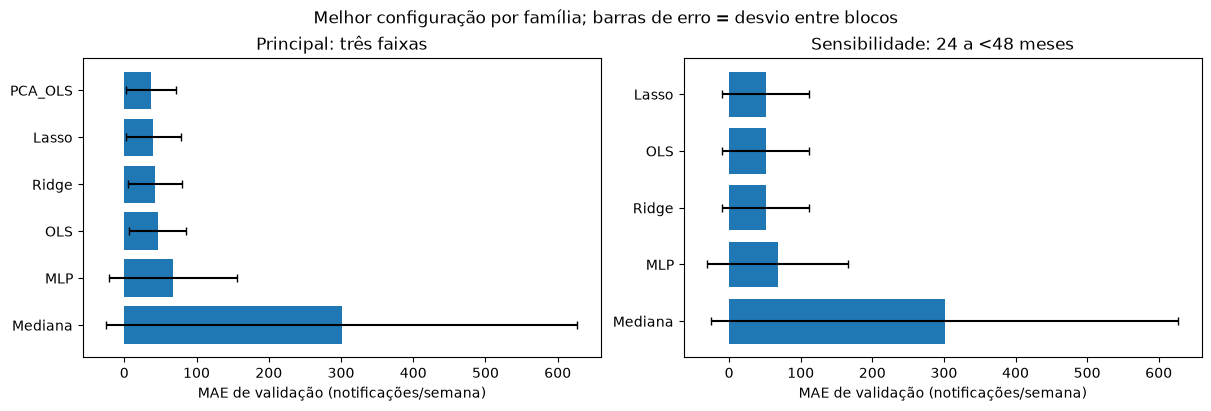

In [32]:
por_bloco = cv.groupby(["referencia", "config", "modelo", "bloco"], sort=False)[["MAE", "RMSE", "R2"]].mean().reset_index()
ranking = por_bloco.groupby(["referencia", "config", "modelo"], sort=False).agg(
    MAE_cv=("MAE", "mean"), desvio_blocos=("MAE", "std"),
    RMSE_cv=("RMSE", "mean"), R2_cv=("R2", "mean")
).reset_index()
elegibilidade = cv.groupby(["referencia", "config"]).status.apply(lambda x: (x == "ok").all())
ranking["elegivel"] = [bool(elegibilidade.loc[(r, c)]) for r, c in zip(ranking.referencia, ranking.config)]
ranking["ordem"] = ranking.config.map({c["id"]: i for i, c in enumerate(GRADE)})
ranking = ranking.sort_values(["referencia", "MAE_cv", "ordem"], kind="stable")
melhores = ranking[ranking.elegivel].drop_duplicates(["referencia", "modelo"])
vencedores = ranking[ranking.elegivel].drop_duplicates("referencia").set_index("referencia")["config"].to_dict()
assert set(vencedores) == set(REFERENCIAS)
display(melhores.drop(columns="ordem").round(3))
for referencia, identificador in vencedores.items():
    config = CONFIGS[identificador]
    valor = ranking.loc[(ranking.referencia == referencia) & (ranking.config == identificador), "MAE_cv"].iloc[0]
    print(referencia, identificador, config, f"MAE de validação = {valor:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, referencia in zip(axes, REFERENCIAS):
    tabela = melhores[melhores.referencia == referencia].sort_values("MAE_cv")
    ax.barh(tabela.modelo, tabela.MAE_cv, xerr=tabela.desvio_blocos, capsize=3)
    ax.invert_yaxis()
    ax.set(title=NOMES_REFERENCIA[referencia], xlabel="MAE de validação (notificações/semana)")
fig.suptitle("Melhor configuração por família; barras de erro = desvio entre blocos")
plt.show()

### PCA com uma única dimensão

Uma componente combina as entradas padronizadas em um único índice linear. Compararemos explicitamente essa alternativa com duas componentes, mantendo as mesmas semanas de validação e escolhendo as defasagens pela validação. Com defasagens, o PCA combina também as contagens das semanas anteriores; sem defasagens, combina apenas as três faixas contemporâneas. A proporção de variância explicada refere-se às entradas, não ao alvo. Reduzir a uma dimensão pode perder informação útil para prever o alvo.


In [33]:
pca_comparacao = ranking[(ranking.referencia == "principal") &
                         (ranking.modelo == "PCA_OLS") & ranking.elegivel].copy()
pca_comparacao["componentes"] = pca_comparacao.config.map(
    lambda identificador: CONFIGS[identificador]["construtor"]["n_components"])
pca_comparacao["defasagens"] = pca_comparacao.config.map(
    lambda identificador: CONFIGS[identificador]["lag"])
display(pca_comparacao[["componentes", "defasagens", "MAE_cv", "RMSE_cv"]].sort_values(
    ["componentes", "defasagens"]).round(3))

,componentes,defasagens,MAE_cv,RMSE_cv
52,1,0,101.914,124.169
53,1,1,75.638,94.018
54,1,2,53.524,65.887
55,2,0,105.506,131.867
56,2,1,54.474,70.766
57,2,2,36.572,47.182


In [34]:
# Interpretação baseada somente na validação.
principal = ranking[(ranking.referencia == "principal") & ranking.elegivel]
best = principal.iloc[0]
pca_best = principal[principal.modelo == "PCA_OLS"].iloc[0]
mlp_best = principal[principal.modelo == "MLP"].iloc[0]
print(f"Leitura da validação: {best['config']}; {best.MAE_cv:.2f}; {pca_best.MAE_cv:.2f}, {mlp_best.MAE_cv:.2f}.")

# Ilustra o PCA escolhido entre seus candidatos, ajustado só no desenvolvimento.
config_pca = CONFIGS[pca_best['config']]
escala_pca = fit_preprocess(train_df, REFERENCIAS["principal"])
Xp, yp = apply_preprocess(train_df, escala_pca)
ajuste_pca = ajustar_config(config_pca, Xp, yp)
pca_ajustado = ajuste_pca["pca"]
nomes_pca = np.array(REFERENCIAS["principal"])[ajuste_pca["indices"]]
display(pd.DataFrame(pca_ajustado.components, index=nomes_pca,
                     columns=[f"PC{i+1}" for i in range(pca_ajustado.n_components)]))
print("Fração de variância das entradas retida:", pca_ajustado.evr.sum())
print("Variância explicada das entradas não equivale a capacidade de prever o alvo.")

Leitura da validação: PCA_OLS_01_lag2; 36.57; 36.57, 67.14.


,PC1,PC2
6-12,0.333617,0.356734
12-24,0.331087,0.436922
24-48,0.330257,0.421385
6-12_lag1,0.337469,-0.043482
12-24_lag1,0.337490,0.061746
24-48_lag1,0.335200,-0.018996
6-12_lag2,0.330836,-0.463582
12-24_lag2,0.333670,-0.350904
24-48_lag2,0.330271,-0.400212


Fração de variância das entradas retida: 0.9845803523677612
Variância explicada das entradas não equivale a capacidade de prever o alvo.


Informações de cima: PCA_OLS_01_lag2 apresentou MAE médio de 36.57 notificações/semana. PCA + OLS obteve 36.57 e a melhor rede neural obteve 67.14. Diferenças pequenas nesta amostra não provam superioridade estatística. A dispersão entre blocos sinaliza que a dificuldade varia ao longo do ciclo sazonal. A média de R² dos blocos não é o R² das previsões concatenadas; blocos de baixa variação podem apresentar R² negativo mesmo com MAE relativamente pequeno.

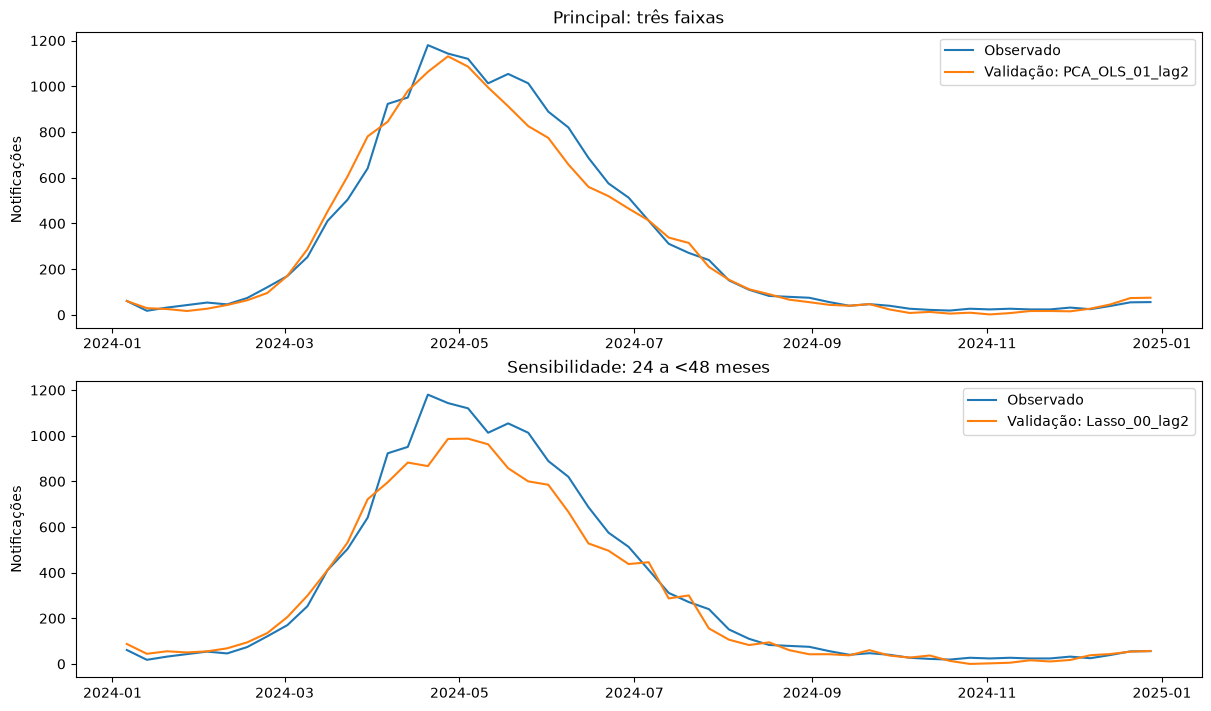

In [35]:
# Previsões de validação; na MLP, média das três sementes avaliadas.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
for ax, (referencia, identificador) in zip(axes, vencedores.items()):
    serie = oof[(oof.referencia == referencia) & (oof.config == identificador)].groupby("semana", as_index=False)[["observado", "previsto"]].mean().sort_values("semana")
    ax.plot(serie.semana, serie.observado, label="Observado")
    ax.plot(serie.semana, serie.previsto, label=f"Validação: {identificador}")
    ax.set(title=NOMES_REFERENCIA[referencia], ylabel="Notificações")
    ax.legend()
plt.show()

### Diagnóstico de treinamento da rede neural

A versão atual da biblioteca fornece `loss_history`. Para cada referência, ajustamos a melhor configuração MLP da validação em todo o desenvolvimento, com a semente predefinida (67). A curva mostra a MSE de treinamento do alvo padronizado, registrada antes da atualização de cada época. Não é erro de validação nem critério para alterar a seleção ou aumentar épocas após consultar o teste.

O regressor continua com uma camada oculta e SGD; o otimizador configurável do novo classificador não se aplica ao nosso problema de regressão.

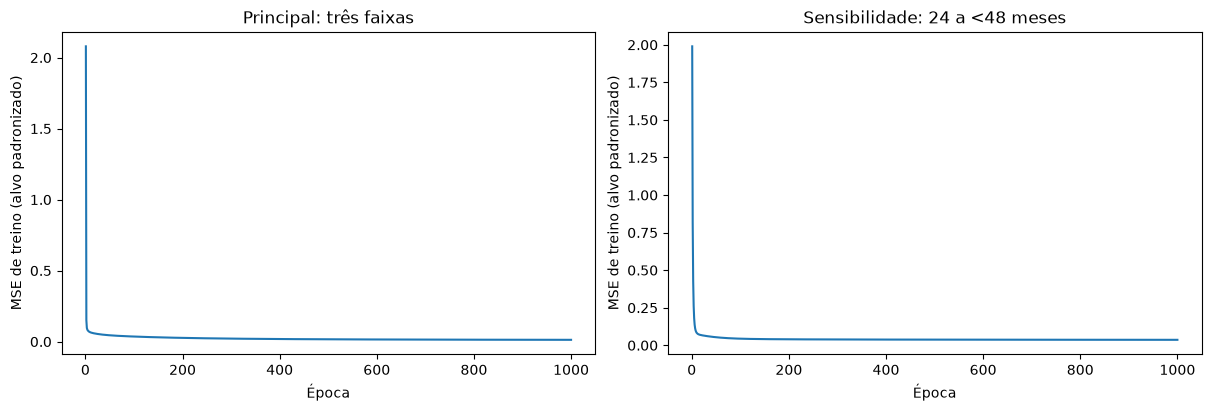

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
curvas_mlp = []
for ax, (referencia, features) in zip(axes, REFERENCIAS.items()):
    candidato = melhores[(melhores.referencia == referencia) & (melhores.modelo == "MLP")].iloc[0]
    escala = fit_preprocess(train_df, features)
    X, y = apply_preprocess(train_df, escala)
    ajustado = ajustar_config(CONFIGS[candidato["config"]], X, y)
    perdas = np.asarray(ajustado["modelo"].loss_history, dtype=float)
    assert len(perdas) == ajustado["modelo"].epochs and np.isfinite(perdas).all()
    ax.plot(np.arange(1, len(perdas)+1), perdas)
    ax.set(title=NOMES_REFERENCIA[referencia], xlabel="Época", ylabel="MSE de treino (alvo padronizado)")
    curvas_mlp.extend({"referencia": referencia, "config": candidato["config"],
                      "epoca": epoca, "mse_treino_padronizado": float(perda)}
                     for epoca, perda in enumerate(perdas, 1))
plt.show()

## 8. Avaliação final no conjunto de teste

### 8.1 Treino final e teste pré-campanha

Congelamos as configurações selecionadas na parte 7. Ajustamos cada vencedor em todo o desenvolvimento e avaliamos no período pré-campanha de 2025, já consultado na versão anterior, junto do baseline. Não reajustamos a grade após observar estes resultados. O teste usa as contagens contemporâneas das faixas de referência e as defasagens selecionadas na validação. As primeiras semanas do teste podem usar contagens das faixas de referência no fim do desenvolvimento; são informações anteriores disponíveis, não valores futuros nem defasagens do alvo.

### 8.2 Métricas, diagnóstico e interpretação

MAE e RMSE estão em notificações por semana; R² pode ser negativo quando o modelo é pior que a média observada no próprio teste. A melhora em MAE é calculada em relação ao baseline treinado no desenvolvimento. Resíduos são observado menos previsto. O diagnóstico ajuda a delimitar a interpretação, mas não serve para refazer a seleção neste mesmo teste.

principal: melhora de MAE sobre baseline = 86.9%; previsões brutas negativas = 0
sensibilidade_24_48: melhora de MAE sobre baseline = 77.8%; previsões brutas negativas = 0


,referencia,modelo,MAE,RMSE,R2
0,principal,PCA_OLS_01_lag2,60.574,103.820,0.967
1,principal,Mediana,463.458,707.274,-0.531
2,sensibilidade_24_48,Lasso_00_lag2,102.753,160.219,0.921
3,sensibilidade_24_48,Mediana,463.458,707.274,-0.531


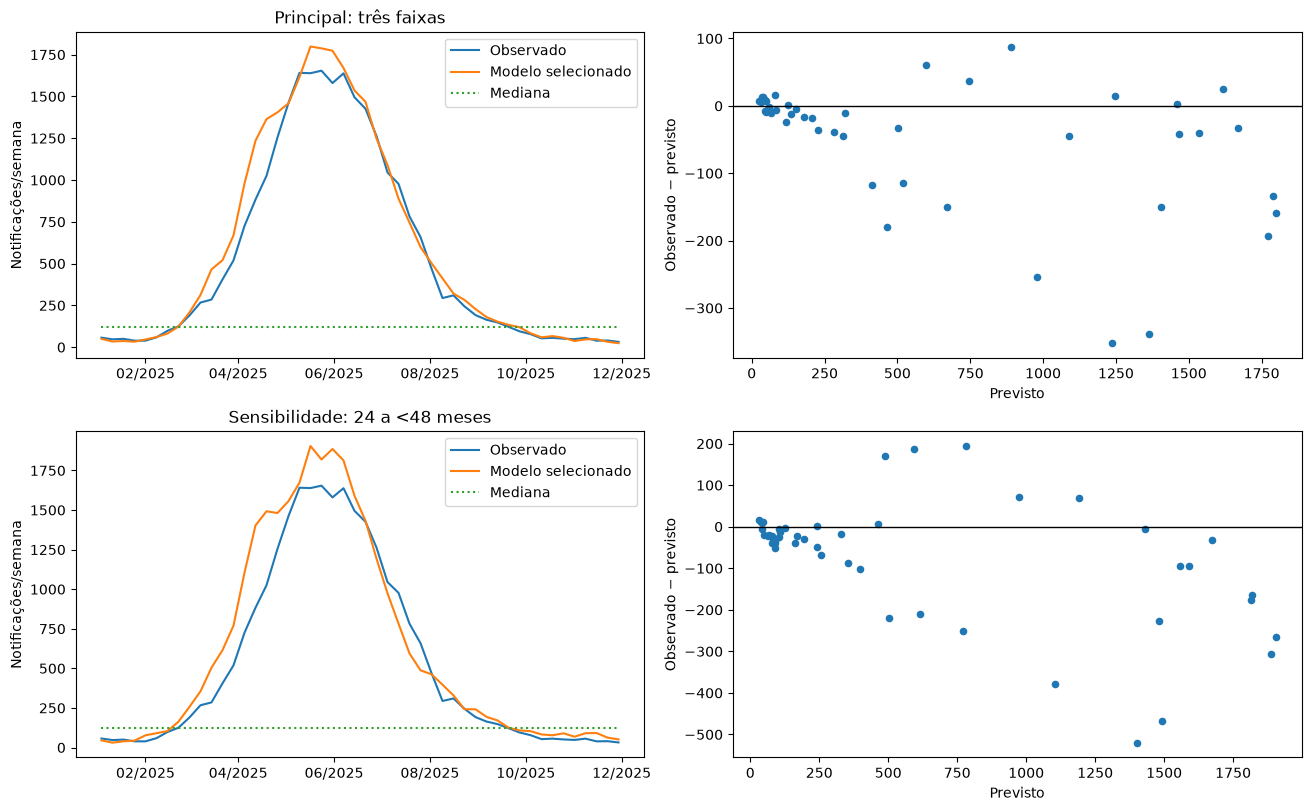

,referencia,vies_medio,correlacao_residuos_lag1,maior_erro_absoluto
0,principal,-47.174,0.72,352.157


,componente,variancia_explicada
0,1,0.962343
1,2,0.022238


,faixa,coef_por_desvio_entrada,coef_por_notificacao
0,6-12,4.5710,0.0380
1,12-24,-2.8808,-0.0355
2,24-48,-1.5815,-0.0353
3,6-12_lag1,40.8030,0.3400
4,12-24_lag1,31.3896,0.3877
5,24-48_lag1,38.3639,0.8586
6,6-12_lag2,77.6673,0.6488
7,12-24_lag2,67.8951,0.8396
8,24-48_lag2,71.9353,1.6123


,referencia,vies_medio,correlacao_residuos_lag1,maior_erro_absoluto
0,sensibilidade_24_48,-71.787,0.831,519.705


,faixa,coef_por_desvio_entrada,coef_por_notificacao
0,24-48,46.0128,1.0273
1,24-48_lag1,72.6980,1.6270
2,24-48_lag2,207.4644,4.6498


In [37]:
modelos_teste, tabelas_teste, resumo_teste = {}, [], []
for referencia, features in REFERENCIAS.items():
    escala = fit_preprocess(train_df, features)
    Xt, yt = apply_preprocess(train_df, escala)
    Xv, yv = apply_preprocess(test_df, escala)
    identificador = vencedores[referencia]
    ajustado = ajustar_config(CONFIGS[identificador], Xt, yt)
    p, negativos = predizer(ajustado, Xv)
    base = treinar_candidato("Mediana", Xt, yt)
    pb, _ = predizer(base, Xv)
    modelos_teste[referencia] = {"ajustado": ajustado, "escala": escala}
    for nome, pred in [(identificador, p), ("Mediana", pb)]:
        resumo_teste.append({"referencia": referencia, "modelo": nome, **metricas(yv, pred)})
    tabelas_teste.append(pd.DataFrame({"semana": test_df.index, "referencia": referencia,
        "observado": yv, "previsto": p, "baseline": pb, "residuo": yv-p}))
    ganho = 100 * (1 - mean_absolute_error(yv, p) / mean_absolute_error(yv, pb))
    print(f"{referencia}: melhora de MAE sobre baseline = {ganho:.1f}%; previsões brutas negativas = {negativos}")
resultado_teste = pd.DataFrame(resumo_teste)
predicoes_teste = pd.concat(tabelas_teste, ignore_index=True)
display(resultado_teste.round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for linha, referencia in enumerate(REFERENCIAS):
    t = predicoes_teste[predicoes_teste.referencia == referencia]
    axes[linha, 0].plot(t.semana, t.observado, label="Observado")
    axes[linha, 0].plot(t.semana, t.previsto, label="Modelo selecionado")
    axes[linha, 0].plot(t.semana, t.baseline, linestyle=":", label="Mediana")
    axes[linha, 0].set(title=NOMES_REFERENCIA[referencia], ylabel="Notificações/semana")
    axes[linha, 0].legend()
    axes[linha, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axes[linha, 0].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    axes[linha, 1].scatter(t.previsto, t.residuo, s=20)
    axes[linha, 1].axhline(0, color="black", linewidth=1)
    axes[linha, 1].set(xlabel="Previsto", ylabel="Observado − previsto")
plt.show()

for referencia in REFERENCIAS:
    t = predicoes_teste[predicoes_teste.referencia == referencia]
    display(pd.DataFrame([{"referencia": referencia, "vies_medio": t.residuo.mean(),
        "correlacao_residuos_lag1": t.residuo.autocorr(1),
        "maior_erro_absoluto": t.residuo.abs().max()}]).round(3))
    modelo = modelos_teste[referencia]["ajustado"]["modelo"]
    if isinstance(modelo, (OrdinaryLeastSquares, Ridge, Lasso)):
        escala = modelos_teste[referencia]["escala"]
        coef = np.asarray(modelo.coef)
        if "pca" in modelos_teste[referencia]["ajustado"]:
            pca = modelos_teste[referencia]["ajustado"]["pca"]
            display(pd.DataFrame({"componente": np.arange(1, len(pca.evr)+1),
                                  "variancia_explicada": pca.evr}))
            coef = pca.components @ coef
        nomes_coef = np.array(escala["features"])[modelos_teste[referencia]["ajustado"]["indices"]]
        std = np.array([escala["parameters"][c]["std"] for c in nomes_coef])
        coef_original = np.divide(coef, std, out=np.zeros_like(coef), where=std > 0)
        display(pd.DataFrame({"faixa": nomes_coef, "coef_por_desvio_entrada": coef,
                              "coef_por_notificacao": coef_original}).round(4))

In [38]:
t = predicoes_teste[predicoes_teste.referencia == "principal"]
m = metricas(t.observado.to_numpy(), t.previsto.to_numpy())
display(Markdown(
    f"**Leitura do teste principal:** MAE = {m['MAE']:.2f}, RMSE = {m['RMSE']:.2f} "
    f"notificações/semana e R² = {m['R2']:.3f}. "
    f"O resíduo médio foi {t.residuo.mean():.2f} (negativo indica superestimação média), "
    f"e a correlação de resíduos entre semanas consecutivas foi {t.residuo.autocorr(1):.3f}. "
    "Erros temporalmente associados limitam inferências baseadas em semanas independentes. "
    "Não calculamos intervalos de confiança iid nem usamos esses diagnósticos para retunar "
    "o modelo neste teste. Uma extensão com dependência temporal exigiria nova avaliação reservada."
))

**Leitura do teste principal:** MAE = 60.57, RMSE = 103.82 notificações/semana e R² = 0.967. O resíduo médio foi -47.17 (negativo indica superestimação média), e a correlação de resíduos entre semanas consecutivas foi 0.720. Erros temporalmente associados limitam inferências baseadas em semanas independentes. Não calculamos intervalos de confiança iid nem usamos esses diagnósticos para retunar o modelo neste teste. Uma extensão com dependência temporal exigiria nova avaliação reservada.

Os coeficientes lineares descrevem associações condicionais: a mudança prevista no alvo para uma unidade da faixa de referência, mantendo as outras fixas. Correlação entre faixas torna essa interpretação instável; não são efeitos causais. Para modelos não lineares, a comparação de erros e resíduos é mais direta que interpretar pesos individuais.

### 8.3 Cenário de referência para 2026

Depois de avaliar o teste, reestimamos os modelos selecionados com todas as semanas completas anteriores à campanha, até 29/11/2025, sem nova busca. Usamos as contagens das faixas de referência observadas na mesma semana de 2026 e nas semanas anteriores exigidas pela configuração selecionada. As defasagens são construídas antes de separar os períodos, preservando o histórico na virada do ano. O ajuste utiliza as semanas pré-campanha com histórico completo para as defasagens; não utiliza o alvo de 2026.

Adotamos **oito semanas de exclusão ao final do extrato**, fixadas como margem operacional antes de examinar as diferenças. Essa margem não foi estimada com históricos de revisões e não garante consolidação. Mostramos também quatro e doze semanas; o maior ou menor contraste não determina o corte escolhido. Usamos 02/11/2026 como data do extrato e semanas encerradas no sábado.

A diferença é **estimado menos observado**: positiva indica menos notificações observadas que no cenário de referência. Não denominamos essa diferença “casos evitados” ou “eficácia”. Ela depende da estabilidade das relações etárias, da testagem, da notificação e das intervenções que afetam as faixas de referência. É uma análise retrospectiva de notificações de SRAG com VSR, não de todas as infecções.

A amplitude entre referências e sementes descreve sensibilidade; não é intervalo de confiança. Sem um desenho causal e uma avaliação de incerteza temporal apropriada, não atribuímos a diferença exclusivamente à vacinação.

C:\Users\lucas\AppData\Local\Temp\ipykernel_16788\3356071424.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(resumo_cenario.round(2))


,referencia,exclusao_semanas,inicio,fim,n_semanas,observado,estimado,estimado_menos_observado,diferenca_percentual_do_estimado,semanas_fora_intervalo_treino
0,principal,4,2026-01-10,2026-10-03,39,13997.0,28342.48,14345.48,50.61,12
1,sensibilidade_24_48,4,2026-01-10,2026-10-03,39,13997.0,28127.29,14130.29,50.24,7
2,principal,8,2026-01-10,2026-09-05,35,13739.0,27760.47,14021.47,50.51,12
3,sensibilidade_24_48,8,2026-01-10,2026-09-05,35,13739.0,27536.13,13797.13,50.11,7
4,principal,12,2026-01-10,2026-08-08,31,13142.0,26317.18,13175.18,50.06,12
5,sensibilidade_24_48,12,2026-01-10,2026-08-08,31,13142.0,26168.73,13026.73,49.78,7


,referencia,faixa,min_historico,max_historico,min_2026,max_2026
0,principal,6-12,10.0,661.0,4.0,756.0
1,principal,12-24,5.0,471.0,1.0,571.0
2,principal,24-48,1.0,268.0,0.0,299.0
3,principal,6-12_lag1,10.0,661.0,12.0,756.0
4,principal,12-24_lag1,5.0,471.0,6.0,571.0
5,principal,24-48_lag1,1.0,268.0,3.0,299.0
6,principal,6-12_lag2,10.0,661.0,11.0,756.0
7,principal,12-24_lag2,5.0,471.0,4.0,571.0
8,principal,24-48_lag2,1.0,268.0,3.0,299.0
9,sensibilidade_24_48,24-48,1.0,268.0,0.0,299.0


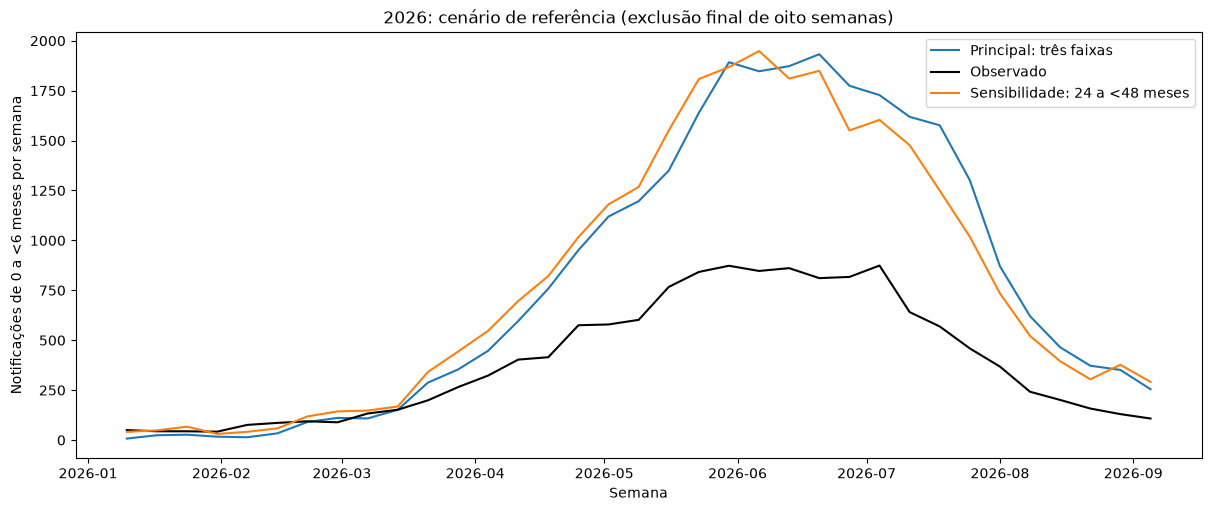

In [39]:
DATA_EXTRATO = pd.Timestamp("2026-11-02")
ATRASO_SEMANAS = 8
historico = painel_modelos.loc[painel_modelos.index <= TEST_END]
assert historico.index.max() < CAMPAIGN_START
cenarios, extrapolacao, variacao_sementes = [], [], []
for referencia, features in REFERENCIAS.items():
    escala = fit_preprocess(historico, features)
    Xh, yh = apply_preprocess(historico, escala)
    Xc, yc = apply_preprocess(scenario_df, escala)
    config = CONFIGS[vencedores[referencia]]
    modelo = ajustar_config(config, Xh, yh)
    pred, _ = predizer(modelo, Xc)
    fora = ((scenario_df[features] < historico[features].min()) |
            (scenario_df[features] > historico[features].max())).any(axis=1)
    cenarios.append(pd.DataFrame({"semana": scenario_df.index, "referencia": referencia,
        "observado": yc, "estimado": pred, "diferenca": pred-yc,
        "fora_intervalo_treino": fora.to_numpy()}))
    for coluna in features:
        extrapolacao.append({"referencia": referencia, "faixa": coluna,
            "min_historico": historico[coluna].min(), "max_historico": historico[coluna].max(),
            "min_2026": scenario_df[coluna].min(), "max_2026": scenario_df[coluna].max()})
    if config["nome"] == "MLP":
        for seed in SEMENTES:
            m = ajustar_config(config, Xh, yh, seed)
            ps, _ = predizer(m, Xc)
            mask = scenario_df.index <= DATA_EXTRATO - pd.Timedelta(weeks=ATRASO_SEMANAS)
            variacao_sementes.append({"referencia": referencia, "seed": seed,
                "total_estimado_8_semanas": ps[mask].sum()})
cenario = pd.concat(cenarios, ignore_index=True)
resumos = []
for atraso in [4, 8, 12]:
    for referencia in REFERENCIAS:
        t = cenario[(cenario.referencia == referencia) &
                    (cenario.semana <= DATA_EXTRATO-pd.Timedelta(weeks=atraso))]
        assert len(t) > 0
        estimado, observado = t.estimado.sum(), t.observado.sum()
        resumos.append({"referencia": referencia, "exclusao_semanas": atraso,
            "inicio": t.semana.min(), "fim": t.semana.max(), "n_semanas": len(t),
            "observado": observado, "estimado": estimado,
            "estimado_menos_observado": estimado-observado,
            "diferenca_percentual_do_estimado": 100*(estimado-observado)/estimado if estimado > 0 else np.nan,
            "semanas_fora_intervalo_treino": int(t.fora_intervalo_treino.sum())})
resumo_cenario = pd.DataFrame(resumos)
display(resumo_cenario.round(2))
display(pd.DataFrame(extrapolacao))
if variacao_sementes:
    display(pd.DataFrame(variacao_sementes).round(2))

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for referencia in REFERENCIAS:
    t = cenario[(cenario.referencia == referencia) &
                (cenario.semana <= DATA_EXTRATO-pd.Timedelta(weeks=ATRASO_SEMANAS))]
    ax.plot(t.semana, t.estimado, label=NOMES_REFERENCIA[referencia])
    if referencia == "principal":
        ax.plot(t.semana, t.observado, color="black", label="Observado")
ax.set(title="2026: cenário de referência (exclusão final de oito semanas)",
       ylabel="Notificações de 0 a <6 meses por semana", xlabel="Semana")
ax.legend()
plt.show()

In [40]:
r = resumo_cenario[(resumo_cenario.referencia == "principal") &
                   (resumo_cenario.exclusao_semanas == ATRASO_SEMANAS)].iloc[0]
display(Markdown(
    f"**Leitura do cenário principal:** entre {r.inicio:%d/%m/%Y} e {r.fim:%d/%m/%Y}, "
    f"o modelo estima {r.estimado:,.1f} notificações, frente a {r.observado:,.0f} observadas. "
    f"A diferença estimado menos observado é {r.estimado_menos_observado:,.1f} "
    f"({r.diferenca_percentual_do_estimado:.1f}% do estimado). "
    f"Em {int(r.semanas_fora_intervalo_treino)} semanas, ao menos uma entrada ficou fora "
    "do intervalo histórico de treinamento. Esse diagnóstico detecta extrapolação marginal, "
    "mas não todas as combinações inéditas entre faixas. A diferença é condicional ao modelo "
    "e às hipóteses; não é uma estimativa causal de notificações evitadas."
))

**Leitura do cenário principal:** entre 10/01/2026 e 05/09/2026, o modelo estima 27,760.5 notificações, frente a 13,739 observadas. A diferença estimado menos observado é 14,021.5 (50.5% do estimado). Em 12 semanas, ao menos uma entrada ficou fora do intervalo histórico de treinamento. Esse diagnóstico detecta extrapolação marginal, mas não todas as combinações inéditas entre faixas. A diferença é condicional ao modelo e às hipóteses; não é uma estimativa causal de notificações evitadas.

## 9. Conclusão

### 9.1 Interpretação

O pipeline permitiu estimar as notificações semanais de SRAG com VSR em menores de seis meses a partir das faixas etárias mais velhas. Foram comparados modelos da biblioteca do grupo com uma referência simples, a mediana do treino, respeitando a ordem temporal na validação e ajustando o pré-processamento somente nos dados de treino de cada bloco.

O melhor resultado na validação foi obtido pela regressão linear com PCA de dois componentes e defasagens de até duas semanas, com MAE médio de **36,57 notificações por semana**. O PCA com apenas um componente teve MAE de 53,52, portanto reduzir tudo a uma dimensão não foi a melhor escolha entre as configurações avaliadas. As defasagens permitiram representar diferenças no momento em que as notificações aumentam nas diferentes faixas etárias.

Na avaliação de 2025, o modelo selecionado apresentou **MAE de 60,57**, RMSE de 103,82 e R² de 0,967, enquanto o baseline teve MAE de 463,46. O modelo acompanhou a variação sazonal melhor que a previsão constante, mas ainda apresentou erros nos períodos de maior circulação e dependência temporal nos resíduos. Como esse período já havia sido examinado antes de algumas alterações no pipeline, esses resultados devem ser tratados como uma avaliação exploratória, e não como uma confirmação independente do desempenho.

A rede neural, com uma camada oculta e diferentes configurações de treinamento, obteve MAE médio de **67,14** na validação principal. Ela superou o baseline, mas não os melhores modelos lineares. Com somente 102 semanas disponíveis no treino após criar as defasagens, não há evidência neste trabalho de que uma rede mais complexa traria melhora. Esse resultado diz respeito às configurações e aos dados avaliados, não à capacidade geral das redes neurais ou da biblioteca.

Para o cenário de 2026, entre 10 de janeiro e 5 de setembro, foram observadas **13.739 notificações**, frente a aproximadamente **27.760 estimadas** pelo modelo principal. A diferença corresponde a 50,51% do total estimado. Usando somente a faixa de 24 a menos de 48 meses como referência, a diferença foi semelhante, de 50,11%, embora essa alternativa tenha apresentado maior erro na avaliação de 2025. Essa proximidade mostra que o resultado foi semelhante nas duas escolhas de referência testadas, mas não comprova a hipótese que sustenta o cenário.

A interpretação depende de a relação histórica entre as faixas etárias continuar válida em 2026. Mudanças na testagem, na notificação e na circulação do vírus também podem influenciar a diferença encontrada. Além disso, há semanas com entradas fora dos intervalos históricos, e a exclusão das oito semanas mais recentes não garante que as notificações anteriores estejam consolidadas. Por isso, **a diferença entre observado e estimado não pode ser interpretada como eficácia da vacinação nem como quantidade comprovada de casos evitados**.

O trabalho mostra que modelos relativamente simples podem representar bem a variação semanal desses dados e superar uma referência constante. Para fortalecer a análise, seria necessário avaliar o modelo em um período ainda não utilizado e acompanhar a atualização das notificações. O principal resultado é um cenário estatístico de referência, acompanhado de suas limitações, e não uma conclusão causal sobre a vacinação.
